In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = "../data/raw/"

cols = (
    ["unit", "cycle"]
    + [f"op{i}" for i in range(1, 4)]
    + [f"s{i}" for i in range(1, 22)]
)

In [2]:
train = pd.read_csv(DATA + "train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv(DATA + "test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul = pd.read_csv(DATA + "RUL_FD001.txt", header=None, names=["RUL"])

print("train shape:", train.shape)
print("test shape:", test.shape)
print("RUL file rows:", len(rul))
print("engines in train:", train["unit"].nunique())
print("engines in test:", test["unit"].nunique())
train.head()

train shape: (20631, 26)
test shape: (13096, 26)
RUL file rows: 100
engines in train: 100
engines in test: 100


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


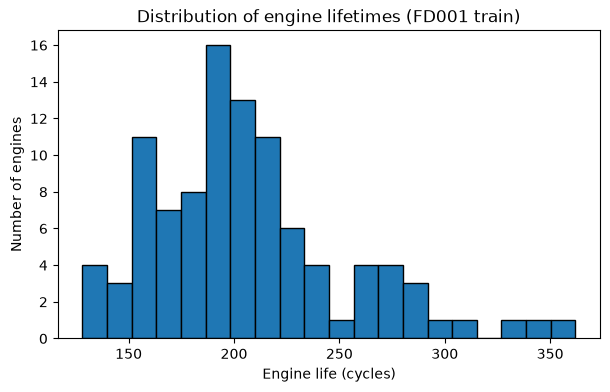

In [3]:
life = train.groupby("unit")["cycle"].max()
print(life.describe())

plt.figure(figsize=(7, 4))
plt.hist(life, bins=20, edgecolor="black")
plt.xlabel("Engine life (cycles)")
plt.ylabel("Number of engines")
plt.title("Distribution of engine lifetimes (FD001 train)")
plt.show()

In [4]:
sensor_cols = [c for c in cols if c.startswith("s")]
setting_cols = ["op1", "op2", "op3"]

print(train[setting_cols + sensor_cols].std().sort_values().head(10))

s1     0.000000e+00
op3    0.000000e+00
s10    0.000000e+00
s19    0.000000e+00
s18    0.000000e+00
s16    3.469531e-18
s5     5.329200e-15
op2    2.930621e-04
s6     1.388985e-03
op1    2.187313e-03
dtype: float64


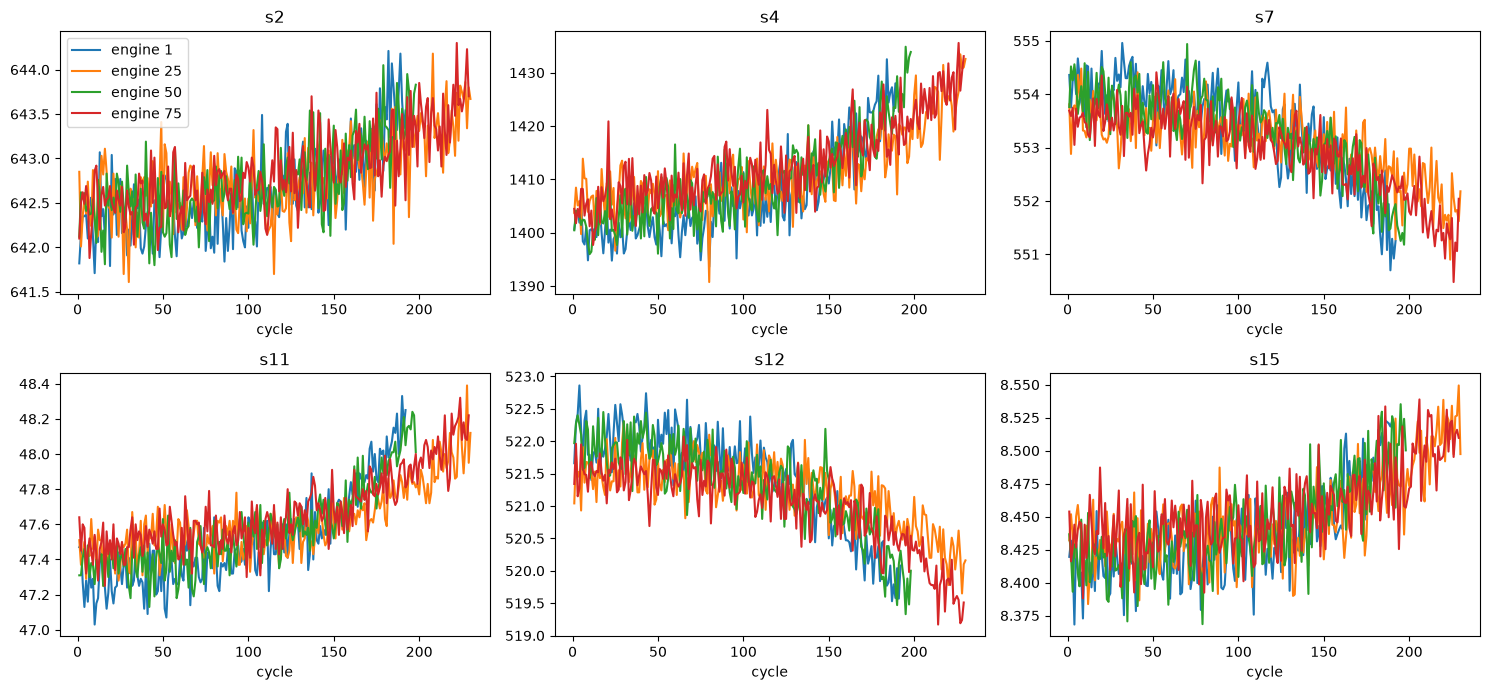

In [5]:
sensors_to_plot = ["s2", "s4", "s7", "s11", "s12", "s15"]
engines = [1, 25, 50, 75]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, s in zip(axes.ravel(), sensors_to_plot):
    for u in engines:
        d = train[train["unit"] == u]
        ax.plot(d["cycle"], d[s], label=f"engine {u}")
    ax.set_title(s)
    ax.set_xlabel("cycle")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [6]:
summary = pd.DataFrame({
    "train_min": train[sensor_cols].min(),
    "train_max": train[sensor_cols].max(),
    "test_min": test[sensor_cols].min(),
    "test_max": test[sensor_cols].max(),
})
summary.round(2)

,train_min,train_max,test_min,test_max
s1,518.67,518.67,518.67,518.67
s2,641.21,644.53,641.13,644.30
s3,1571.04,1616.91,1569.04,1607.55
s4,1382.25,1441.49,1384.39,1433.36
s5,14.62,14.62,14.62,14.62
s6,21.60,21.61,21.60,21.61
s7,549.85,556.06,550.88,555.84
s8,2387.90,2388.56,2387.89,2388.30
s9,9021.73,9244.59,9024.53,9155.03
s10,1.30,1.30,1.30,1.30


. The training set has 100 engines with lifetimes from 128 to 362 cycles (mean about 206), so lifetimes vary a lot between engines.

. 7 columns (s1, s5, s10, s16, s18, s19, op3) are constant and will be dropped.

. s2, s4, s11, s15 rise and s7, s12 fall as failure approaches. The signal is weak compared with the noise, so smoothing is needed.

. Train and test sensor ranges are consistent, so I expect no distribution shift on FD001.